In [ ]:
!pip install pandas

In [ ]:
from sklearn.ensemble import RandomForestClassifier
# Import required libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score





In [ ]:
adverse_model = RandomForestClassifier(random_state=42)
response_model = RandomForestClassifier(random_state=42)


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Example data
data = pd.DataFrame({
    'Gender': [],
    'name': [],
    'Response': []
})

label_encoders = {}
for col in ['Gender', 'name', 'Response']:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

print(data)


Empty DataFrame
Columns: [Gender, name, Response]
Index: []


In [ ]:
# Enhanced Random Forest Classifier with hyperparameters
adverse_model = RandomForestClassifier(
    n_estimators=200,       # Number of trees
    max_depth=10,           # Maximum depth of trees
    min_samples_split=5,    # Minimum samples to split a node
    min_samples_leaf=2,     # Minimum samples to form a leaf node
    class_weight='balanced',  # Handles class imbalance
    random_state=42         # Ensures reproducibility
)

response_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42
)


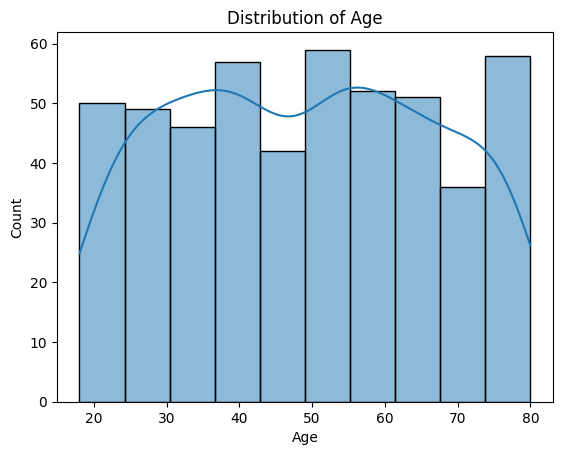

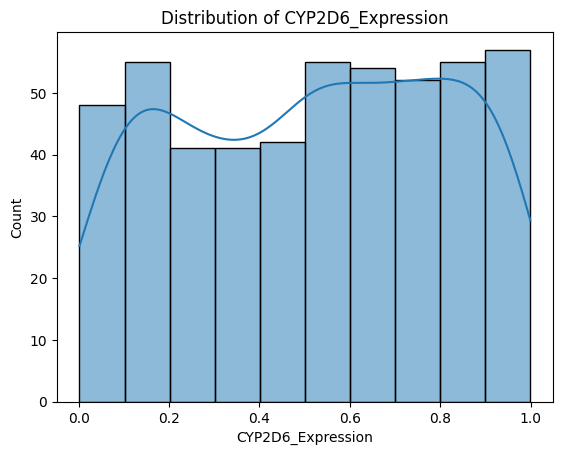

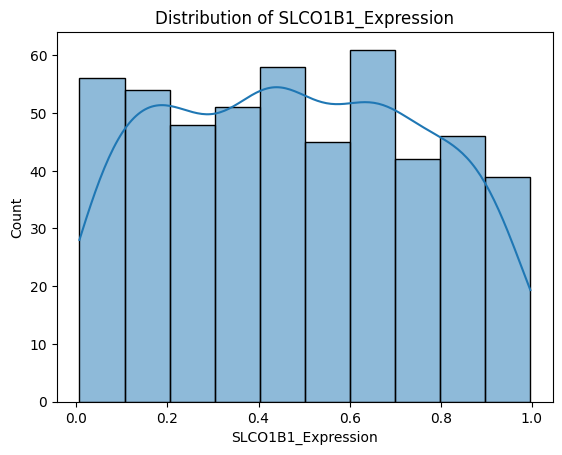

/tmp/ipython-input-2727566809.py:57: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_train[col].fillna(X_train[col].median(), inplace=True)
/tmp/ipython-input-2727566809.py:58: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Step 1: Load Dataset
file_path = 'modified_gene_expression_dataset.csv'  # Replace with actual file path
data = pd.read_csv(file_path)

# Step 2: Data Cleaning
# Drop duplicate columns if present
data = data.loc[:, ~data.columns.duplicated()]

# Handle missing values
# Fill numeric columns with the median and categorical columns with 'Unknown'
numeric_cols = data.select_dtypes(include=np.number).columns
categorical_cols = data.select_dtypes(include='object').columns

data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].median())
data[categorical_cols] = data[categorical_cols].fillna('Unknown')

# Encode categorical variables
if 'Gender' in data.columns:
    data['Gender'] = data['Gender'].map({'Male': 0, 'Female': 1})

# Step 3: EDA (Optional Visualization)
# Plot distributions of numeric features
for col in ['Age', 'CYP2D6_Expression', 'SLCO1B1_Expression']:
    if col in data.columns:
        sns.histplot(data[col], kde=True)
        plt.title(f'Distribution of {col}')
        plt.show()

# Step 4: Train-Test Split
# Replace Drug_Name with Name attribute
X = data.drop(columns=['Response'])  # Drop 'Response' as the target variable
y_response = data['Response']

# Split into train-test sets
X_train, X_test, y_train_resp, y_test_resp = train_test_split(X, y_response, test_size=0.2, random_state=42)

# Step 5: Handle Missing Values in Train/Test
# Define numerical and categorical features
numerical_features = ['Age', 'CYP2D6_Expression', 'SLCO1B1_Expression', 'CYP2C9_Expression', 'CYP3A4_Expression']
categorical_features = ['Name']  # Replaced 'Drug_Name' with 'Name'

# Fill numeric columns with the median
for col in numerical_features:
    if col in X_train.columns:
        X_train[col].fillna(X_train[col].median(), inplace=True)
        X_test[col].fillna(X_train[col].median(), inplace=True)  # Use train median for consistency

# Fill categorical columns with 'Unknown'
for col in categorical_features:
    if col in X_train.columns:
        X_train[col].fillna('Unknown', inplace=True)



In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import numpy as np

# Load the dataset
data = pd.read_csv('modified_gene_expression_dataset.csv')

# Step 1: Data Preprocessing
# Drop non-relevant columns (e.g., Patient_ID)
data = data.drop(['Patient_ID'], axis=1)

# Encode categorical variables
label_encoders = {}
for col in ['Gender', 'name', 'Response']:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Separate features and target
X = data.drop(['Response'], axis=1)
Y_response = data['Response']

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, Y_response_train, Y_response_test = train_test_split(
    X_scaled, Y_response, test_size=0.2, random_state=42
)

# Step 2: Model Training for Response
response_model = RandomForestClassifier(random_state=42)
response_model.fit(X_train, Y_response_train)

# Step 3: Evaluation for Response
Y_response_pred = response_model.predict(X_test)
print("Classification Report for Response Prediction:")
print(classification_report(Y_response_test, Y_response_pred))

# Step 4: Feature Importance Analysis
feature_importances_response = pd.DataFrame({
    'Feature': X.columns,
    'Importance': response_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop Features for Response Prediction:")
print(feature_importances_response.head())

# Step 5: User Input and Prediction
def predict_response():
    print("Enter patient details for prediction:")

    # Collect input from the user
    age = int(input("Age: "))
    gender = input("Gender (Male/Female): ")
    name = input("Name: ")
    cyp2d6 = float(input("CYP2D6 Expression: "))
    slco1b1 = float(input("SLCO1B1 Expression: "))
    cyp2c9 = float(input("CYP2C9 Expression: "))
    cyp3a4 = float(input("CYP3A4 Expression: "))

    # Encode categorical inputs
    gender_encoded = label_encoders['Gender'].transform([gender])[0]
    name_encoded = label_encoders['name'].transform([name])[0]

    # Create feature array
    input_features = np.array([[age, gender_encoded, name_encoded, cyp2d6, slco1b1, cyp2c9, cyp3a4]])

    # Scale numerical features
    input_features_scaled = scaler.transform(input_features)

    # Predict Response
    response_prediction = response_model.predict(input_features_scaled)

    # Decode predictions
    response_decoded = label_encoders['Response'].inverse_transform(response_prediction)[0]

    print(f"Predicted Response: {response_decoded}")

# Run the prediction function
predict_response()

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Classification Report for Response Prediction:
              precision    recall  f1-score   support

           0       0.58      0.90      0.71        59
           1       0.33      0.09      0.14        34
           2       0.00      0.00      0.00         7

    accuracy                           0.56       100
   macro avg       0.31      0.33      0.28       100
weighted avg       0.46      0.56      0.46       100


Top Features for Response Prediction:
              Feature  Importance
3   CYP2D6_Expression    0.176748
2                name    0.166983
5   CYP2C9_Expression    0.163887
4  SLCO1B1_Expression    0.162520
6   CYP3A4_Expression    0.161941
Enter patient details for prediction:
Age: 34
Gender (Male/Female): Male
Name: mannitol
CYP2D6 Expression: 0.5
SLCO1B1 Expression: 0.8
CYP2C9 Expression: 0.9
CYP3A4 Expression: 0.4
Predicted Response: Effective


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
!pip install streamlit pyngrok


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 57.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 71.6 MB/s eta 0:00:00


In [ ]:
from pyngrok import ngrok

# Replace with your ngrok token
ngrok.set_auth_token("341EvRmn9v60ItCj0hM9hOHU9Ds_7k2axYRoTArCw2jd33hCy")

# Start streamlit tunnel
public_url = ngrok.connect(8501)
public_url


<NgrokTunnel: "https://drumlier-zariyah-nondoctrinally.ngrok-free.dev" -> "http://localhost:8501">

In [ ]:
public_url = ngrok.connect(8501)
public_url
